In [2]:

import pandas as pd
import numpy as np

# Load datasets directly from Colab
train_df = pd.read_csv("/content/KM6312_Lexicon_1000_Train.csv")
val_df = pd.read_csv("/content/KM6312_Lexicon_1000_Validation.csv")

# Basic validation
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

# Check missing values
assert train_df[["lyrics", "label"]].notna().all().all()
assert val_df[["lyrics", "label"]].notna().all().all()

# Check overlap
assert set(train_df["song_id"]).isdisjoint(set(val_df["song_id"]))

print("\nData validation passed!")

display(train_df.head(3))


Training samples: 700
Validation samples: 150

Training label distribution:
label
Happy      290
Relaxed    208
Sad        123
Angry       79
Name: count, dtype: int64

Validation label distribution:
label
Happy      62
Relaxed    45
Sad        26
Angry      17
Name: count, dtype: int64

Data validation passed!


,sample_id,song_id,song_title,artist,year,lyrics,label
0,NEW0718,1393,Until You Come Back To Me (That's What I'm Gon...,Aretha Franklin,1974,Though you don’t call anymore I sit and wait i...,Relaxed
1,NEW0644,4746,Dead And Gone,T.I. feat. Justin Timberlake,2009,"Ayy, let me kick it to you right quick, man No...",Angry
2,NEW0469,472,Bread And Butter,Newbeats,1964,I like bread and butter I like toast and jam T...,Relaxed


In [3]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Prepare inputs
X_train = train_df["lyrics"].astype(str)
y_train = train_df["label"]

X_val = val_df["lyrics"].astype(str)
y_val = val_df["label"]

# Build baseline model
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train on 700 songs
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")


Baseline model trained successfully!


Validation Accuracy: 0.4733
Validation Macro-F1: 0.3119

Classification Report:
              precision    recall  f1-score   support

       Happy       0.51      0.90      0.65        62
     Relaxed       0.33      0.27      0.30        45
         Sad       0.00      0.00      0.00        26
       Angry       1.00      0.18      0.30        17

    accuracy                           0.47       150
   macro avg       0.46      0.34      0.31       150
weighted avg       0.42      0.47      0.39       150



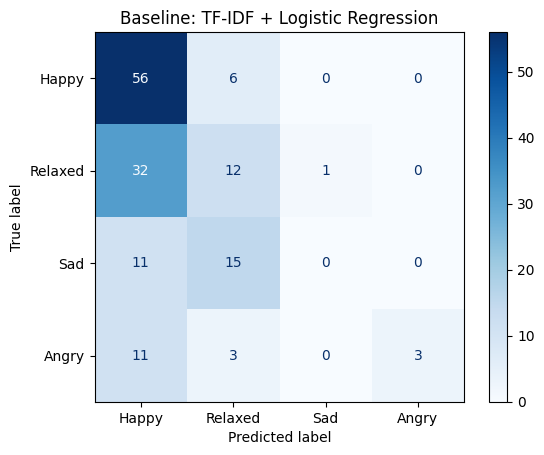

In [4]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict validation set
y_pred = baseline_model.predict(X_val)

# Evaluation
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

labels = ["Happy", "Relaxed", "Sad", "Angry"]

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred,
    labels=labels,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    labels=labels,
    cmap="Blues"
)

plt.title("Baseline: TF-IDF + Logistic Regression")
plt.show()


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Balanced Logistic Regression
balanced_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression trained!")


Balanced Logistic Regression trained!


Balanced Validation Accuracy: 0.5467
Balanced Validation Macro-F1: 0.5071

Classification Report:
              precision    recall  f1-score   support

       Happy       0.72      0.71      0.72        62
     Relaxed       0.43      0.40      0.41        45
         Sad       0.40      0.46      0.43        26
       Angry       0.47      0.47      0.47        17

    accuracy                           0.55       150
   macro avg       0.51      0.51      0.51       150
weighted avg       0.55      0.55      0.55       150



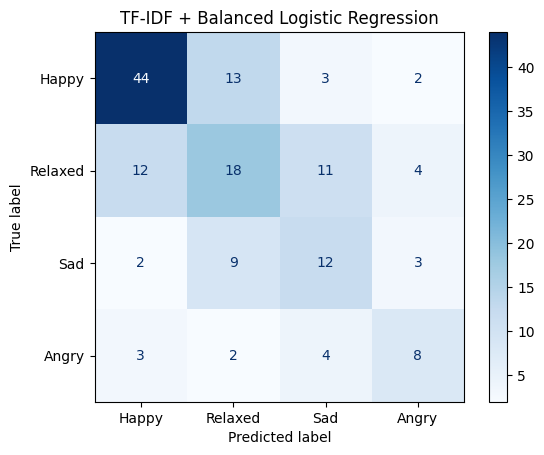


MODEL COMPARISON
Original LR Macro-F1: 0.3119
Balanced LR Macro-F1: 0.5071


In [6]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

labels = ["Happy", "Relaxed", "Sad", "Angry"]

# Predict
balanced_pred = balanced_model.predict(X_val)

# Metrics
balanced_acc = accuracy_score(y_val, balanced_pred)

balanced_f1 = f1_score(
    y_val,
    balanced_pred,
    average="macro",
    zero_division=0
)

print("Balanced Validation Accuracy:",
      round(balanced_acc, 4))

print("Balanced Validation Macro-F1:",
      round(balanced_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    balanced_pred,
    labels=labels,
    zero_division=0
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    balanced_pred,
    labels=labels,
    cmap="Blues"
)

plt.title("TF-IDF + Balanced Logistic Regression")
plt.show()

# Compare with original baseline
print("\nMODEL COMPARISON")
print("Original LR Macro-F1:", round(macro_f1, 4))
print("Balanced LR Macro-F1:", round(balanced_f1, 4))


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

svm_model.fit(X_train, y_train)

print("Balanced SVM trained successfully!")


Balanced SVM trained successfully!


SVM Validation Accuracy: 0.5933
SVM Validation Macro-F1: 0.5369

Classification Report:
              precision    recall  f1-score   support

       Happy       0.71      0.81      0.76        62
     Relaxed       0.50      0.44      0.47        45
         Sad       0.48      0.42      0.45        26
       Angry       0.47      0.47      0.47        17

    accuracy                           0.59       150
   macro avg       0.54      0.54      0.54       150
weighted avg       0.58      0.59      0.59       150



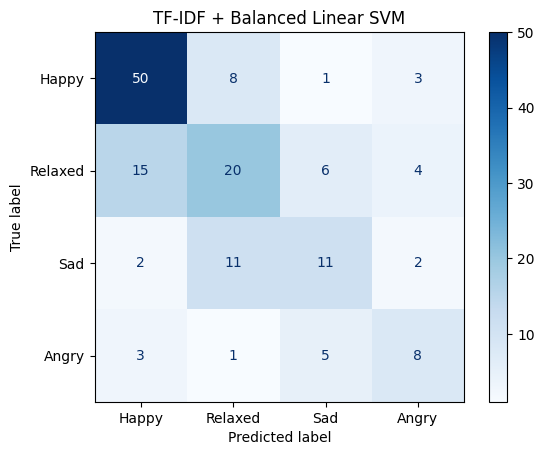

,Model,Validation Accuracy,Validation Macro-F1
0,Original LR,0.4733,0.3119
1,Balanced LR,0.5467,0.5071
2,Balanced SVM,0.5933,0.5369


In [8]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

class_names = ["Happy", "Relaxed", "Sad", "Angry"]

svm_pred = svm_model.predict(X_val)

svm_acc = accuracy_score(y_val, svm_pred)
svm_f1 = f1_score(
    y_val, svm_pred,
    average="macro",
    zero_division=0
)

print(f"SVM Validation Accuracy: {svm_acc:.4f}")
print(f"SVM Validation Macro-F1: {svm_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    svm_pred,
    labels=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_pred,
    labels=class_names,
    cmap="Blues"
)

plt.title("TF-IDF + Balanced Linear SVM")
plt.show()

# Compare all three models
comparison = pd.DataFrame([
    ["Original LR", accuracy, macro_f1],
    ["Balanced LR", balanced_acc, balanced_f1],
    ["Balanced SVM", svm_acc, svm_f1]
], columns=["Model", "Validation Accuracy", "Validation Macro-F1"])

display(comparison.round(4))


In [9]:

!pip -q install transformers

import pandas as pd
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Fix random seed
torch.manual_seed(42)
np.random.seed(42)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

# Reload datasets
train_df = pd.read_csv(
    "/content/KM6312_Lexicon_1000_Train.csv"
)
val_df = pd.read_csv(
    "/content/KM6312_Lexicon_1000_Validation.csv"
)

print("Training:", len(train_df))
print("Validation:", len(val_df))


Device: cuda
Training: 700
Validation: 150


In [10]:

import torch.nn.functional as F

model_name = "bert-base-uncased"

class_names = ["Happy", "Relaxed", "Sad", "Angry"]

label2id = {
    name: i for i, name in enumerate(class_names)
}
id2label = {
    i: name for name, i in label2id.items()
}

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Dataset
class LyricsDataset(Dataset):
    def __init__(self, df):
        self.tokens = tokenizer(
            df["lyrics"].fillna("").astype(str).tolist(),
            truncation=True,
            padding="max_length",
            max_length=256,
            return_tensors="pt"
        )

        self.targets = torch.tensor(
            df["label"].map(label2id).tolist(),
            dtype=torch.long
        )

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        item = {
            key: value[idx]
            for key, value in self.tokens.items()
        }
        item["labels"] = self.targets[idx]
        return item

# Data loaders
train_loader = DataLoader(
    LyricsDataset(train_df),
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    LyricsDataset(val_df),
    batch_size=8,
    shuffle=False
)

# Calculate weights from training labels only
counts = train_df["label"].value_counts()

weights = [
    len(train_df) / (4 * counts[name])
    for name in class_names
]

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for name, weight in zip(class_names, weights):
    print(f"{name}: {weight:.3f}")

# Initialize model
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=4,
    label2id=label2id,
    id2label=id2label
).to(device)

print("\nWeighted BERT is ready!")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Class weights:
Happy: 0.603
Relaxed: 0.841
Sad: 1.423
Angry: 2.215


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Weighted BERT is ready!


In [11]:

optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

best_f1 = -1
best_preds = None
best_true = None

for epoch in range(3):

    # Training
    bert_model.train()
    total_loss = 0

    for batch in train_loader:
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        optimizer.zero_grad()

        outputs = bert_model(
            **{
                k: v for k, v in batch.items()
                if k != "labels"
            }
        )

        loss = F.cross_entropy(
            outputs.logits,
            batch["labels"],
            weight=class_weights
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(), 1.0
        )
        optimizer.step()

        total_loss += loss.item()

    # Validation
    bert_model.eval()
    all_preds = []
    all_true = []

    with torch.no_grad():
        for batch in val_loader:
            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = bert_model(
                **{
                    k: v for k, v in batch.items()
                    if k != "labels"
                }
            )

            preds = outputs.logits.argmax(dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_true.extend(
                batch["labels"].cpu().tolist()
            )

    acc = accuracy_score(all_true, all_preds)
    macro_f1 = f1_score(
        all_true, all_preds,
        average="macro",
        zero_division=0
    )

    print(f"\nEpoch {epoch + 1}")
    print(
        f"Train Loss: {total_loss / len(train_loader):.4f}"
    )
    print(f"Validation Accuracy: {acc:.4f}")
    print(f"Validation Macro-F1: {macro_f1:.4f}")
    print("-" * 35)

    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_preds = all_preds.copy()
        best_true = all_true.copy()

        bert_model.save_pretrained(
            "/content/best_weighted_bert_1000"
        )
        tokenizer.save_pretrained(
            "/content/best_weighted_bert_1000"
        )

print("\nBest Validation Macro-F1:",
      round(best_f1, 4))

print("\nClassification Report:")
print(classification_report(
    best_true,
    best_preds,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))



Epoch 1
Train Loss: 1.3672
Validation Accuracy: 0.4867
Validation Macro-F1: 0.3448
-----------------------------------


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 2
Train Loss: 1.1680
Validation Accuracy: 0.6000
Validation Macro-F1: 0.5540
-----------------------------------


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 3
Train Loss: 0.7605
Validation Accuracy: 0.6267
Validation Macro-F1: 0.5901
-----------------------------------


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best Validation Macro-F1: 0.5901

Classification Report:
              precision    recall  f1-score   support

       Happy       0.78      0.79      0.78        62
     Relaxed       0.53      0.42      0.47        45
         Sad       0.50      0.62      0.55        26
       Angry       0.53      0.59      0.56        17

    accuracy                           0.63       150
   macro avg       0.58      0.60      0.59       150
weighted avg       0.63      0.63      0.62       150



In [12]:

# Continue training from Epoch 3 to Epoch 5
# Do not reinitialize the model or optimizer

for epoch in range(3, 5):

    bert_model.train()
    total_loss = 0

    for batch in train_loader:
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        optimizer.zero_grad()

        outputs = bert_model(
            **{k: v for k, v in batch.items()
               if k != "labels"}
        )

        loss = F.cross_entropy(
            outputs.logits,
            batch["labels"],
            weight=class_weights
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(), 1.0
        )

        optimizer.step()
        total_loss += loss.item()

    # Validation
    bert_model.eval()
    all_preds = []
    all_true = []

    with torch.no_grad():
        for batch in val_loader:
            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = bert_model(
                **{k: v for k, v in batch.items()
                   if k != "labels"}
            )

            preds = outputs.logits.argmax(dim=1)

            all_preds.extend(preds.cpu().tolist())
            all_true.extend(
                batch["labels"].cpu().tolist()
            )

    acc = accuracy_score(all_true, all_preds)

    macro_f1 = f1_score(
        all_true,
        all_preds,
        average="macro",
        zero_division=0
    )

    print(f"\nEpoch {epoch + 1}")
    print(f"Train Loss: {total_loss / len(train_loader):.4f}")
    print(f"Validation Accuracy: {acc:.4f}")
    print(f"Validation Macro-F1: {macro_f1:.4f}")

    # Save only if performance improves
    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_preds = all_preds.copy()
        best_true = all_true.copy()

        bert_model.save_pretrained(
            "/content/best_weighted_bert_1000"
        )

        print("New best model saved!")

print("\nBest Validation Macro-F1:",
      round(best_f1, 4))

print("\nBest Classification Report:")
print(classification_report(
    best_true,
    best_preds,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))



Epoch 4
Train Loss: 0.4148
Validation Accuracy: 0.6400
Validation Macro-F1: 0.6136


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

New best model saved!

Epoch 5
Train Loss: 0.2060
Validation Accuracy: 0.6000
Validation Macro-F1: 0.5511

Best Validation Macro-F1: 0.6136

Best Classification Report:
              precision    recall  f1-score   support

       Happy       0.69      0.84      0.76        62
     Relaxed       0.56      0.33      0.42        45
         Sad       0.58      0.69      0.63        26
       Angry       0.65      0.65      0.65        17

    accuracy                           0.64       150
   macro avg       0.62      0.63      0.61       150
weighted avg       0.63      0.64      0.62       150



In [13]:

import torch
import numpy as np
import random
import torch.nn.functional as F

from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Fix random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 2. Calculate original balanced weights
class_names = ["Happy", "Relaxed", "Sad", "Angry"]

counts = train_df["label"].value_counts()

base_weights = {
    name: len(train_df) / (4 * counts[name])
    for name in class_names
}

# 3. Increase Relaxed weight by 50%
multipliers = {
    "Happy": 1.0,
    "Relaxed": 1.5,
    "Sad": 1.0,
    "Angry": 1.0
}

custom_weights = torch.tensor([
    base_weights[name] * multipliers[name]
    for name in class_names
], dtype=torch.float32).to(device)

print("Custom Class Weights:")
for name, weight in zip(class_names, custom_weights):
    print(f"{name}: {weight.item():.3f}")

# 4. Initialize a fresh BERT
custom_bert = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=4,
    label2id=label2id,
    id2label=id2label
).to(device)

custom_optimizer = torch.optim.AdamW(
    custom_bert.parameters(),
    lr=2e-5
)

# 5. Train up to 5 epochs
best_custom_f1 = -1
best_custom_true = None
best_custom_preds = None

for epoch in range(5):

    custom_bert.train()
    total_loss = 0

    for batch in train_loader:
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        custom_optimizer.zero_grad()

        outputs = custom_bert(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        loss = F.cross_entropy(
            outputs.logits,
            batch["labels"],
            weight=custom_weights
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            custom_bert.parameters(), 1.0
        )

        custom_optimizer.step()
        total_loss += loss.item()

    # Validation
    custom_bert.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for batch in val_loader:
            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = custom_bert(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            predictions = outputs.logits.argmax(dim=1)

            y_pred.extend(predictions.cpu().tolist())
            y_true.extend(batch["labels"].cpu().tolist())

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    print(f"\nEpoch {epoch + 1}")
    print(f"Train Loss: {total_loss / len(train_loader):.4f}")
    print(f"Validation Accuracy: {acc:.4f}")
    print(f"Validation Macro-F1: {macro_f1:.4f}")

    # Save the best checkpoint
    if macro_f1 > best_custom_f1:
        best_custom_f1 = macro_f1
        best_custom_true = y_true.copy()
        best_custom_preds = y_pred.copy()

        custom_bert.save_pretrained(
            "/content/best_custom_weighted_bert_1000"
        )

print("\nBest Custom Macro-F1:",
      round(best_custom_f1, 4))

print("\nBest Classification Report:")
print(classification_report(
    best_custom_true,
    best_custom_preds,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))


Custom Class Weights:
Happy: 0.603
Relaxed: 1.262
Sad: 1.423
Angry: 2.215


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Epoch 1
Train Loss: 1.3581
Validation Accuracy: 0.3933
Validation Macro-F1: 0.2985


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 2
Train Loss: 1.1768
Validation Accuracy: 0.5800
Validation Macro-F1: 0.5725


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 3
Train Loss: 0.8067
Validation Accuracy: 0.6400
Validation Macro-F1: 0.6257


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Epoch 4
Train Loss: 0.4526
Validation Accuracy: 0.6133
Validation Macro-F1: 0.5878

Epoch 5
Train Loss: 0.2245
Validation Accuracy: 0.5600
Validation Macro-F1: 0.5116

Best Custom Macro-F1: 0.6257

Best Classification Report:
              precision    recall  f1-score   support

       Happy       0.83      0.69      0.75        62
     Relaxed       0.50      0.60      0.55        45
         Sad       0.61      0.54      0.57        26
       Angry       0.57      0.71      0.63        17

    accuracy                           0.64       150
   macro avg       0.63      0.63      0.63       150
weighted avg       0.66      0.64      0.65       150



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Final Test Accuracy: 0.6
Final Test Macro-F1: 0.6093

Classification Report:
              precision    recall  f1-score   support

       Happy       0.77      0.60      0.67        62
     Relaxed       0.45      0.58      0.50        45
         Sad       0.59      0.50      0.54        26
       Angry       0.64      0.82      0.72        17

    accuracy                           0.60       150
   macro avg       0.61      0.62      0.61       150
weighted avg       0.63      0.60      0.60       150



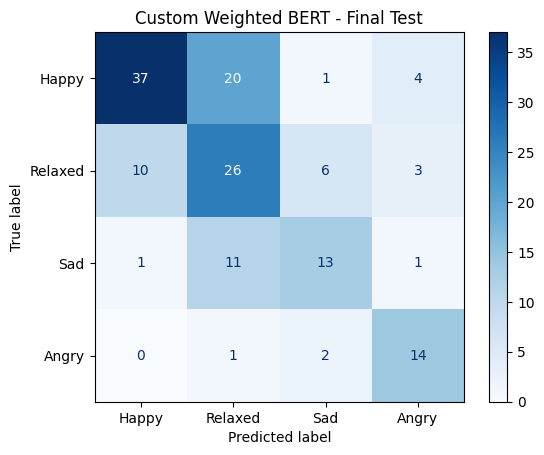

In [14]:

import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Load the untouched test set
test_df = pd.read_csv(
    "/content/KM6312_Lexicon_1000_Test.csv"
)

test_loader = DataLoader(
    LyricsDataset(test_df),
    batch_size=8,
    shuffle=False
)

# Load the best Custom Weighted BERT (Epoch 3)
final_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/best_custom_weighted_bert_1000"
).to(device)

final_model.eval()

test_true = []
test_pred = []

with torch.no_grad():
    for batch in test_loader:
        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        outputs = final_model(**inputs)
        predictions = outputs.logits.argmax(dim=1)

        test_pred.extend(predictions.cpu().tolist())
        test_true.extend(batch["labels"].tolist())

print("Final Test Accuracy:",
      round(accuracy_score(test_true, test_pred), 4))

print("Final Test Macro-F1:",
      round(f1_score(
          test_true, test_pred,
          average="macro",
          zero_division=0
      ), 4))

class_names = ["Happy", "Relaxed", "Sad", "Angry"]

print("\nClassification Report:")
print(classification_report(
    test_true,
    test_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    test_true,
    test_pred,
    labels=[0, 1, 2, 3],
    display_labels=class_names,
    cmap="Blues"
)

plt.title("Custom Weighted BERT - Final Test")
plt.show()


In [15]:

from google.colab import drive
from transformers import AutoTokenizer
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Best model: Custom Weighted BERT, Epoch 3
source_dir = "/content/best_custom_weighted_bert_1000"

# Permanent storage
save_dir = "/content/drive/MyDrive/KM6312_Emotion_Final_Model"

assert os.path.isdir(source_dir), "Best model folder not found!"

# Save the original BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
tokenizer.save_pretrained(source_dir)

# Copy the entire model folder to Drive
shutil.copytree(
    source_dir,
    save_dir,
    dirs_exist_ok=True
)

print("Final model saved to:")
print(save_dir)
print("\nSaved files:")
print(os.listdir(save_dir))


Mounted at /content/drive
Final model saved to:
/content/drive/MyDrive/KM6312_Emotion_Final_Model

Saved files:
['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']


In [16]:

import pandas as pd
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from tqdm.auto import tqdm

# 1. Load the full Master Dataset
master_df = pd.read_csv(
    "/content/KM6312_Master_Dataset_12col.csv"
)

print("Total songs:", len(master_df))
print("Columns:", master_df.columns.tolist())

assert len(master_df) == 6075
assert master_df["song_id"].is_unique
assert master_df["bert_lyrics"].notna().all()

# 2. Load the saved model from Google Drive
model_dir = "/content/drive/MyDrive/KM6312_Emotion_Final_Model"

tokenizer = AutoTokenizer.from_pretrained(model_dir)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_model = AutoModelForSequenceClassification.from_pretrained(
    model_dir
).to(device)

final_model.eval()

# 3. Confirm class order
class_names = [
    final_model.config.id2label[i]
    for i in range(4)
]

print("Classes:", class_names)

assert class_names == [
    "Happy", "Relaxed", "Sad", "Angry"
], "Class mapping does not match training!"

# 4. Predict all songs
batch_size = 16
texts = master_df["bert_lyrics"].astype(str).tolist()

all_probs = []

for start in tqdm(range(0, len(texts), batch_size)):

    batch_texts = texts[start:start + batch_size]

    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        outputs = final_model(**inputs)

        probs = torch.softmax(
            outputs.logits, dim=1
        )

    all_probs.append(probs.cpu().numpy())

# 5. Convert results
probabilities = np.vstack(all_probs)
predicted_ids = probabilities.argmax(axis=1)

master_df["predicted_emotion"] = [
    class_names[i] for i in predicted_ids
]

master_df["emotion_confidence"] = (
    probabilities.max(axis=1)
)

for i, name in enumerate(class_names):
    master_df[f"prob_{name.lower()}"] = probabilities[:, i]

print("\nPrediction completed!")
print("Total predicted:", len(master_df))

print("\nPredicted emotion distribution:")
print(master_df["predicted_emotion"].value_counts())


Total songs: 6075
Columns: ['song_id', 'song_title', 'artist', 'year', 'rank', 'original_lyrics', 'bert_lyrics', 'word_count', 'unique_word_count', 'lexical_diversity', 'decade', 'language']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Classes: ['Happy', 'Relaxed', 'Sad', 'Angry']


  0%|          | 0/380 [00:00<?, ?it/s]


Prediction completed!
Total predicted: 6075

Predicted emotion distribution:
predicted_emotion
Relaxed    2525
Happy      1904
Angry       847
Sad         799
Name: count, dtype: int64


In [17]:

import os

output_dir = "/content/drive/MyDrive/KM6312_Emotion_Results"
os.makedirs(output_dir, exist_ok=True)

# Select useful columns for team sharing
result_columns = [
    "song_id",
    "song_title",
    "artist",
    "year",
    "rank",
    "predicted_emotion",
    "emotion_confidence",
    "prob_happy",
    "prob_relaxed",
    "prob_sad",
    "prob_angry"
]

predictions_df = master_df[result_columns].copy()

# Save compact prediction results
predictions_path = (
    output_dir + "/KM6312_Emotion_6075_Predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False,
    encoding="utf-8-sig"
)

# Save full Master with added predictions
master_path = (
    output_dir + "/KM6312_Master_With_Emotion.csv"
)

master_df.to_csv(
    master_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved prediction results:")
print(predictions_path)

print("\nSaved full Master Dataset:")
print(master_path)

print("\nFinal sample:")
display(predictions_df.head(10))


Saved prediction results:
/content/drive/MyDrive/KM6312_Emotion_Results/KM6312_Emotion_6075_Predictions.csv

Saved full Master Dataset:
/content/drive/MyDrive/KM6312_Emotion_Results/KM6312_Master_With_Emotion.csv

Final sample:


,song_id,song_title,artist,year,rank,predicted_emotion,emotion_confidence,prob_happy,prob_relaxed,prob_sad,prob_angry
0,1,The Battle Of New Orleans,Johnny Horton,1959,1,Angry,0.702491,0.044382,0.128885,0.124242,0.702491
1,2,Mack The Knife,Bobby Darin,1959,2,Sad,0.414511,0.055524,0.346569,0.414511,0.183396
2,3,Personality,Lloyd Price,1959,3,Happy,0.829837,0.829837,0.147409,0.012689,0.010066
3,4,Venus,Frankie Avalon,1959,4,Happy,0.824313,0.824313,0.153370,0.012328,0.009990
4,5,Lonely Boy,Paul Anka,1959,5,Relaxed,0.569719,0.127874,0.569719,0.279449,0.022958
5,6,Dream Lover,Bobby Darin,1959,6,Relaxed,0.561002,0.393267,0.561002,0.032785,0.012945
6,7,The Three Bells,Browns,1959,7,Happy,0.799392,0.799392,0.173737,0.018353,0.008518
7,8,Come Softly To Me,Fleetwoods,1959,8,Happy,0.554899,0.554899,0.402398,0.026858,0.015844
8,9,Kansas City,Wilbert Harrison,1959,9,Relaxed,0.601282,0.070603,0.601282,0.277205,0.050910
9,10,Mr. Blue,Fleetwoods,1959,10,Relaxed,0.725608,0.184262,0.725608,0.076534,0.013596
